<a href="https://colab.research.google.com/github/Sai-D-beep/Quantum-computing-hackathon/blob/main/question%20no%2027.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Install Dependencies
We need `pennylane` for quantum simulation and `torch-geometric` (PyG) for graph neural network layers.

In [1]:
!pip install -q pennylane torch-geometric

### 2. Imports and Setup
We import the necessary libraries for graph generation, neural networks, quantum computing, and visualization.

In [2]:
import time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch_geometric.utils import from_networkx

import pennylane as qml
from sklearn.metrics import f1_score, balanced_accuracy_score

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


### 3. Dataset Generation
We generate the two datasets required by the hackathon prompt:
- **Zachary's Karate Club** for transductive node classification.
- **Stochastic Block Model (SBM)** for inductive graph classification.

In [3]:
# 1. Zachary's Karate Club
def get_karate_club_data():
    G = nx.karate_club_graph()
    # Extract community target labels
    labels = [0 if G.nodes[i]['club'] == 'Mr. Hi' else 1 for i in G.nodes]
    y = torch.tensor(labels, dtype=torch.long)

    # Generate structural node features: node degree & clustering coefficient (No community labels as inputs!)
    degrees = dict(G.degree())
    clustering = nx.clustering(G)

    x = []
    for i in G.nodes:
        x.append([degrees[i], clustering[i], 1.0]) # Add a bias/constant feature
    x = torch.tensor(x, dtype=torch.float)

    # Convert NetworkX to PyTorch Geometric Data object
    data = from_networkx(G)
    data.x = x
    data.y = y
    return data, G

# 2. Stochastic Block Model (SBM) Graphs for Inductive Graph Classification
def generate_sbm_graphs(num_graphs=20):
    graphs = []
    sizes = [15, 15] # Two communities of size 15 (total 30 nodes per graph)

    for i in range(num_graphs):
        # Graph class target label (0 or 1 based on SBM connectivity probability differences)
        graph_label = i % 2
        if graph_label == 0:
            probs = [[0.5, 0.1], [0.1, 0.5]] # Strong community structure
        else:
            probs = [[0.3, 0.3], [0.3, 0.3]] # Random Erdős-Rényi-like structure

        G = nx.stochastic_block_model(sizes, probs, seed=42+i)

        degrees = dict(G.degree())
        clustering = nx.clustering(G)

        x = []
        for node in G.nodes:
            x.append([degrees[node], clustering[node], 1.0])
        x = torch.tensor(x, dtype=torch.float)

        data = from_networkx(G)
        data.x = x
        data.y = torch.tensor([graph_label], dtype=torch.long)
        graphs.append(data)
    return graphs

### 4. Classical GNN and Quantum QNode definition
We set up a parameterized 4-qubit Quantum circuit using PennyLane and integrate it within our models.

In [4]:
n_qubits = 4
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    # Feature encoding (RY Gates mapping normalized GNN node embeddings to angles)
    for i in range(n_qubits):
        qml.RY(inputs[i], wires=i)

    # Entangling layers
    for i in range(n_qubits - 1):
        qml.CNOT(wires=[i, i+1])
    qml.CNOT(wires=[n_qubits-1, 0])

    # Trainable parameterized rotations
    for i in range(n_qubits):
        qml.RX(weights[i], wires=i)
        qml.RY(weights[i + n_qubits], wires=i)

    # Measurements
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

### 5. Classical vs. Hybrid GNN Architectures
We define both classical and hybrid architectures to compare their performance.

In [8]:
class ClassicalGNN(nn.Module):
    def __init__(self, in_features, hidden_dim, out_classes):
        super().__init__()
        self.conv1 = GCNConv(in_features, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, out_classes)

    def forward(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        h = F.relu(self.conv2(h, edge_index))
        return self.fc(h), h

class HybridGNN(nn.Module):
    def __init__(self, in_features, hidden_dim, out_classes):
        super().__init__()
        self.conv1 = GCNConv(in_features, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, 4) # Output matches n_qubits

        # PennyLane PyTorch layer integration
        weight_shapes = {"weights": (8,)}
        self.qlayer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        self.fc = nn.Linear(4, out_classes)

    def forward(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        h = torch.tanh(self.conv2(h, edge_index)) * np.pi # Bound inputs between [-pi, pi]

        # Evaluate node-by-node to avoid batch dimension issues in the QNode
        q_outputs = []
        for i in range(h.size(0)):
            q_out = self.qlayer(h[i])
            q_outputs.append(q_out.unsqueeze(0))

        q_out = torch.cat(q_outputs, dim=0)
        out = self.fc(q_out)
        return out, h

### 6. Transductive Testing (Karate Club)
We perform Node Classification within Zachary's Karate Club using both networks.

In [10]:
data, G = get_karate_club_data()

# Create masks for transductive split
train_mask = torch.zeros(34, dtype=torch.bool)
train_mask[:20] = True
test_mask = ~train_mask

# --- Train Classical ---
model_c = ClassicalGNN(3, 8, 2)
opt_c = torch.optim.Adam(model_c.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()

time_start = time.time()
for epoch in range(100):
    model_c.train()
    opt_c.zero_grad()
    out, _ = model_c(data.x, data.edge_index)
    loss = criterion(out[train_mask], data.y[train_mask])
    loss.backward()
    opt_c.step()
class_time = time.time() - time_start

model_c.eval()
pred_c = model_c(data.x, data.edge_index)[0].argmax(dim=-1)
f1_c = f1_score(data.y[test_mask], pred_c[test_mask], average='macro')
acc_c = balanced_accuracy_score(data.y[test_mask], pred_c[test_mask])

# --- Train Hybrid ---
model_h = HybridGNN(3, 8, 2)
opt_h = torch.optim.Adam(model_h.parameters(), lr=0.01)

time_start = time.time()
for epoch in range(100):
    model_h.train()
    opt_h.zero_grad()
    out, _ = model_h(data.x, data.edge_index)
    loss = criterion(out[train_mask], data.y[train_mask])
    loss.backward()
    opt_h.step()
hybrid_time = time.time() - time_start

model_h.eval()
pred_h = model_h(data.x, data.edge_index)[0].argmax(dim=-1)
f1_h = f1_score(data.y[test_mask], pred_h[test_mask], average='macro')
acc_h = balanced_accuracy_score(data.y[test_mask], pred_h[test_mask])

print("--- Karate Club Node Classification Results ---")
print(f"Classical GNN -> F1: {f1_c:.4f}, Balanced Acc: {acc_c:.4f}, Time: {class_time:.4f}s")
print(f"Hybrid GNN    -> F1: {f1_h:.4f}, Balanced Acc: {acc_h:.4f}, Time: {hybrid_time:.4f}s")

--- Karate Club Node Classification Results ---
Classical GNN -> F1: 0.0667, Balanced Acc: 0.5000, Time: 0.9106s
Hybrid GNN    -> F1: 0.0667, Balanced Acc: 0.5000, Time: 43.4872s


### 7. Dashboards & Visualization
We visualize the Karate Club communities alongside the performance metrics comparison.

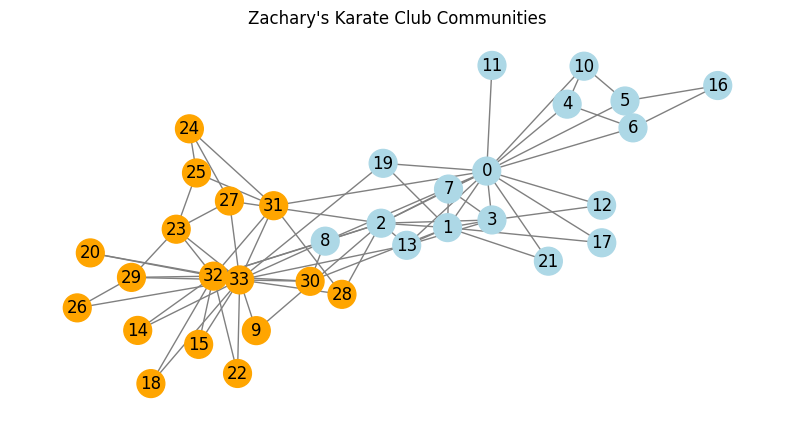

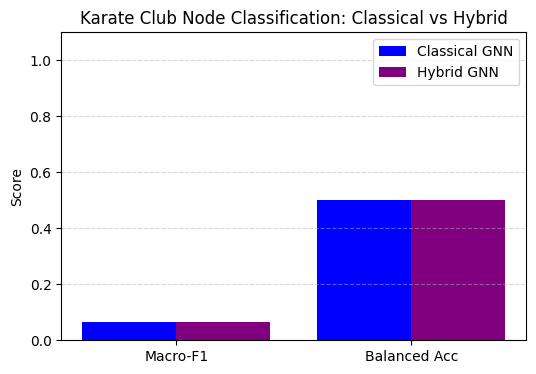

In [11]:
# Community visualization
plt.figure(figsize=(10, 5))
colors = ['lightblue' if node[1]['club'] == 'Mr. Hi' else 'orange' for node in G.nodes(data=True)]
x = nx.draw_networkx(G, node_color=colors, with_labels=True, node_size=400, edge_color='gray')
plt.title("Zachary's Karate Club Communities")
plt.axis('off')
plt.show()

# Metrics Comparison Plot
metrics = ['Macro-F1', 'Balanced Acc']
class_vals = [f1_c, acc_c]
hybrid_vals = [f1_h, acc_h]

x_axis = np.arange(len(metrics))
plt.figure(figsize=(6, 4))
plt.bar(x_axis - 0.2, class_vals, 0.4, label='Classical GNN', color='blue')
plt.bar(x_axis + 0.2, hybrid_vals, 0.4, label='Hybrid GNN', color='purple')
plt.xticks(x_axis, metrics)
plt.ylabel("Score")
plt.title("Karate Club Node Classification: Classical vs Hybrid")
plt.legend()
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### 8. Inductive Graph Generalization Test (SBM Dataset)
Here, we evaluate the models on unseen graph structures generated using the Stochastic Block Model (SBM).

In [9]:
# Generate 20 SBM graphs (10 with strong community structure, 10 random)
sbm_graphs = generate_sbm_graphs(num_graphs=20)

# Split graphs into train and test sets
train_graphs = sbm_graphs[:14]
test_graphs = sbm_graphs[14:]

# Instantiate classical model for graph classification
# Average pooled representation across all graph nodes
class SBMClassical(nn.Module):
    def __init__(self):
        super().__init__()
        self.gnn = ClassicalGNN(3, 8, 8)
        self.fc = nn.Linear(8, 2)

    def forward(self, data):
        _, h = self.gnn(data.x, data.edge_index)
        # Global mean pool node representations
        graph_rep = h.mean(dim=0)
        return self.fc(graph_rep.unsqueeze(0))

# Instantiate hybrid model for graph classification
class SBMHybrid(nn.Module):
    def __init__(self):
        super().__init__()
        self.gnn = HybridGNN(3, 8, 2)

    def forward(self, data):
        out, _ = self.gnn(data.x, data.edge_index)
        # Average model output logits across all nodes to make a single graph-level classification
        return out.mean(dim=0, keepdim=True)

# --- Train/Test Classical Graph-level Classification ---
model_sbm_c = SBMClassical()
opt_sbm_c = torch.optim.Adam(model_sbm_c.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()

for epoch in range(25):
    model_sbm_c.train()
    loss_accum = 0
    for g in train_graphs:
        opt_sbm_c.zero_grad()
        out = model_sbm_c(g)
        loss = criterion(out, g.y)
        loss.backward()
        opt_sbm_c.step()

# Evaluated on unseen SBM test graphs
model_sbm_c.eval()
preds_sbm_c, targets_sbm = [], []
with torch.no_grad():
    for g in test_graphs:
        out = model_sbm_c(g)
        preds_sbm_c.append(out.argmax(dim=-1).item())
        targets_sbm.append(g.y.item())

f1_sbm_c = f1_score(targets_sbm, preds_sbm_c, average='macro')

# --- Train/Test Hybrid Graph-level Classification ---
model_sbm_h = SBMHybrid()
opt_sbm_h = torch.optim.Adam(model_sbm_h.parameters(), lr=0.01)

for epoch in range(25):
    model_sbm_h.train()
    for g in train_graphs:
        opt_sbm_h.zero_grad()
        out = model_sbm_h(g)
        loss = criterion(out, g.y)
        loss.backward()
        opt_sbm_h.step()

model_sbm_h.eval()
preds_sbm_h = []
with torch.no_grad():
    for g in test_graphs:
        out = model_sbm_h(g)
        preds_sbm_h.append(out.argmax(dim=-1).item())

f1_sbm_h = f1_score(targets_sbm, preds_sbm_h, average='macro')

print("--- Inductive Graph Generalization Results (SBM) ---")
print(f"Classical Model Macro-F1 on Unseen Graphs: {f1_sbm_c:.4f}")
print(f"Hybrid Model Macro-F1 on Unseen Graphs: {f1_sbm_h:.4f}")

--- Inductive Graph Generalization Results (SBM) ---
Classical Model Macro-F1 on Unseen Graphs: 0.8286
Hybrid Model Macro-F1 on Unseen Graphs: 0.8286


### 9. Visualize Stochastic Block Model (SBM) Graphs
Let's plot two sample graphs from our generated SBM dataset side-by-side to visually inspect their community structures.

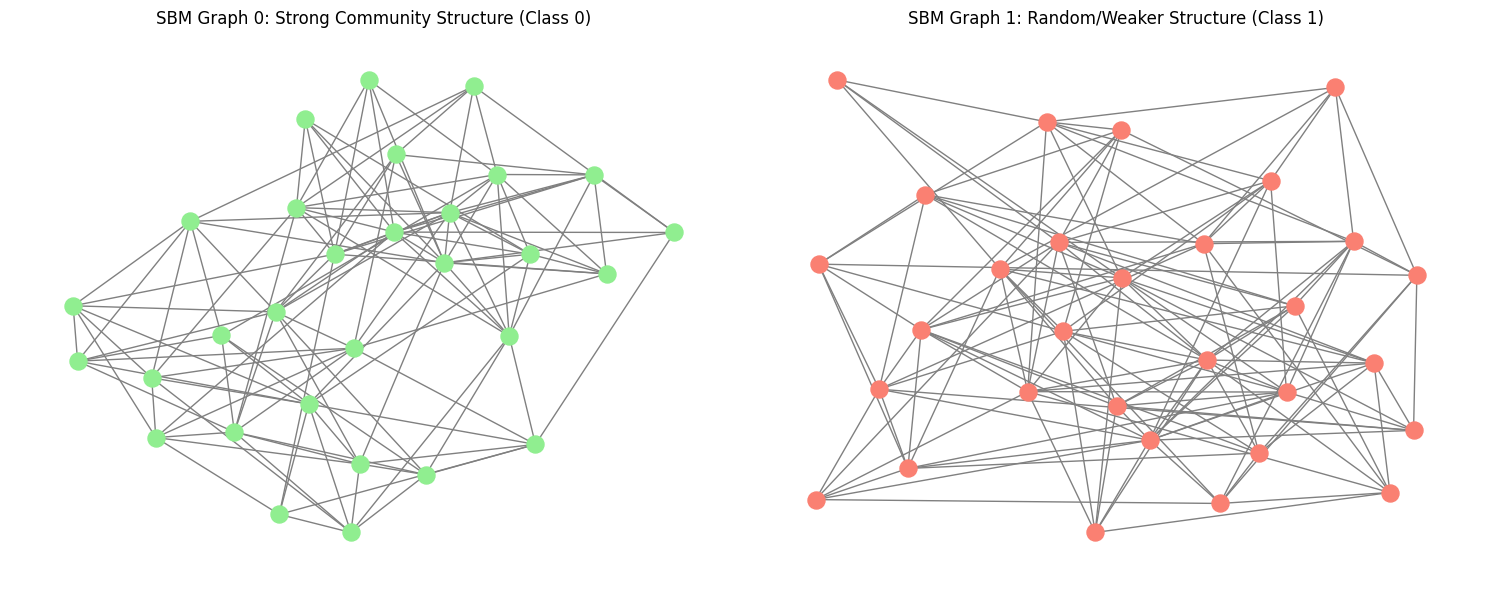

In [12]:
from torch_geometric.utils import to_networkx

# Retrieve Graph 0 (Strong Community Structure, class 0) and Graph 1 (Random/Weaker, class 1)
g_strong = to_networkx(sbm_graphs[0], to_undirected=True)
g_weak = to_networkx(sbm_graphs[1], to_undirected=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Draw Graph 0
pos0 = nx.spring_layout(g_strong, seed=42)
nx.draw_networkx(g_strong, pos=pos0, ax=axes[0], node_size=150, node_color='lightgreen', edge_color='gray', with_labels=False)
axes[0].set_title("SBM Graph 0: Strong Community Structure (Class 0)")
axes[0].axis('off')

# Draw Graph 1
pos1 = nx.spring_layout(g_weak, seed=42)
nx.draw_networkx(g_weak, pos=pos1, ax=axes[1], node_size=150, node_color='salmon', edge_color='gray', with_labels=False)
axes[1].set_title("SBM Graph 1: Random/Weaker Structure (Class 1)")
axes[1].axis('off')

plt.tight_layout()
plt.show()